In [ ]:
import pandas as pd, numpy as np
p = pd.read_csv("painel.csv")
p["mes"] = pd.to_datetime(p["mes"])

feats = ["lag1","lag2","lag3","lag6","lag12","roll3","roll12","m","ano","logpop"]
tr = p[p.mes < "2025-01-01"]
te = p[p.mes >= "2025-01-01"]

print(p.shape, p.y.sum())
print(p.mes.min(), p.mes.max())
print(p[feats + ["y"]].isna().sum().sum(), "valores nulos")
print(len(tr), "treino |", len(te), "teste")

(16830, 14) 19428
2013-01-01 00:00:00 2026-09-01 00:00:00
0 valores nulos
14688 treino | 2142 teste


In [ ]:
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

res = {}
res["ingenuo"] = te["lag1"]
res["sazonal_ingenuo"] = te["lag12"]
res["media_12m"] = te["roll12"]

for k, v in res.items():
    print(f"{k:16s} MAE={mae(te.y, v):.3f}  RMSE={rmse(te.y, v):.3f}")

print("zero sempre      MAE=%.3f  RMSE=%.3f" % (mae(te.y, np.zeros(len(te))), rmse(te.y, np.zeros(len(te)))))

ingenuo          MAE=0.627  RMSE=1.359
sazonal_ingenuo  MAE=0.630  RMSE=1.357
media_12m        MAE=0.542  RMSE=1.043
zero sempre      MAE=0.764  RMSE=3.149


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression().fit(tr[feats], tr.y)
pred_lin = lr.predict(te[feats])
res["linear"] = np.clip(pred_lin, 0, None)

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(tr[feats], tr.y)
res["random_forest"] = rf.predict(te[feats])

res["zero_sempre"] = np.zeros(len(te))

out = pd.DataFrame({k: [mae(te.y, v), rmse(te.y, v)] for k, v in res.items()}, index=["MAE", "RMSE"]).T
print(out.sort_values("MAE").round(3))
print((pred_lin < 0).sum(), "previsões negativas na linear (antes do clip)")

                   MAE   RMSE
linear           0.541  1.067
media_12m        0.542  1.043
random_forest    0.614  1.077
ingenuo          0.627  1.359
sazonal_ingenuo  0.630  1.357
zero_sempre      0.764  3.149
293 previsões negativas na linear (antes do clip)


In [ ]:
print("média real:", round(te.y.mean(), 3))
for k, v in res.items():
    print(f"{k:16s} média prevista = {np.mean(v):.3f}")

print(pd.Series(rf.feature_importances_, feats).sort_values(ascending=False).round(3))
print(pd.Series(lr.coef_, feats).round(3))

média real: 0.764
ingenuo          média prevista = 0.770
sazonal_ingenuo  média prevista = 0.840
media_12m        média prevista = 0.797
linear           média prevista = 0.770
random_forest    média prevista = 0.932
zero_sempre      média prevista = 0.000
roll12    0.357
logpop    0.271
roll3     0.260
lag2      0.032
lag1      0.031
ano       0.017
m         0.011
lag12     0.011
lag3      0.006
lag6      0.005
dtype: float64
lag1      0.187
lag2      0.098
lag3     -0.031
lag6     -0.042
lag12     0.049
roll3     0.084
roll12    0.612
m         0.003
ano      -0.002
logpop    0.045
dtype: float64


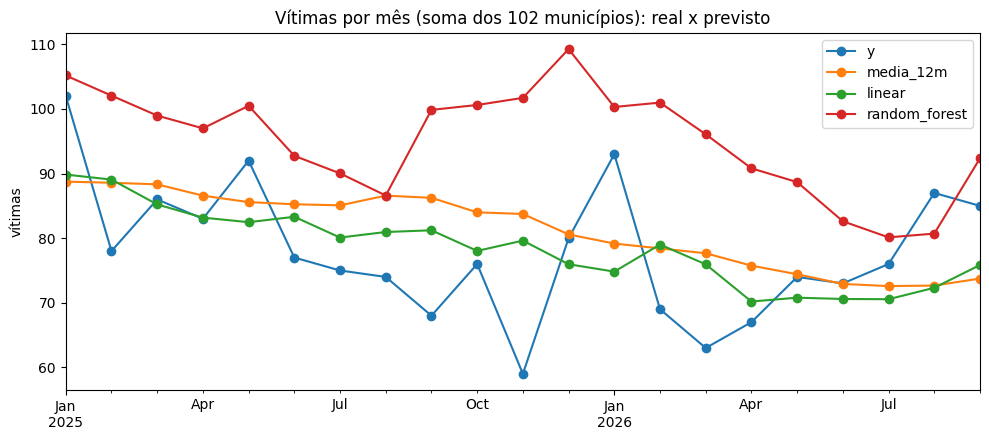

              y  media_12m  linear  random_forest
mes                                              
2025-01-01  102       88.8    89.8          105.2
2025-02-01   78       88.6    89.1          102.1
2025-03-01   86       88.3    85.2           99.0
2025-04-01   83       86.6    83.2           97.0
2025-05-01   92       85.6    82.5          100.5
2025-06-01   77       85.2    83.3           92.8
2025-07-01   75       85.1    80.1           90.0
2025-08-01   74       86.6    81.0           86.6
2025-09-01   68       86.2    81.2           99.9
2025-10-01   76       84.0    78.0          100.6
2025-11-01   59       83.8    79.6          101.7
2025-12-01   80       80.6    76.0          109.3
2026-01-01   93       79.2    74.8          100.3
2026-02-01   69       78.4    79.0          101.0
2026-03-01   63       77.7    76.0           96.1
2026-04-01   67       75.8    70.2           90.8
2026-05-01   74       74.4    70.8           88.7
2026-06-01   73       72.9    70.6           82.6


In [ ]:
import matplotlib.pyplot as plt

t = te[["mes", "y"]].copy()
t["media_12m"] = res["media_12m"].values
t["linear"] = res["linear"]
t["random_forest"] = res["random_forest"]
s = t.groupby("mes").sum()

ax = s.plot(figsize=(10, 4.5), marker="o", title="Vítimas por mês (soma dos 102 municípios): real x previsto")
ax.set_ylabel("vítimas")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("rq3_previsto_real.png", dpi=150)
plt.show()
print(s.round(1))

In [ ]:
variantes = {
    "rf_sem_logpop": [f for f in feats if f != "logpop"],
    "rf_sem_logpop_ano": [f for f in feats if f not in ("logpop", "ano")],
    "rf_so_passado": ["lag1", "lag2", "lag3", "lag6", "lag12", "roll3", "roll12"],
}

linhas = [["random_forest (original)", mae(te.y, res["random_forest"]), rmse(te.y, res["random_forest"]), np.mean(res["random_forest"])]]
for nome, fs in variantes.items():
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(tr[fs], tr.y)
    pr = m.predict(te[fs])
    res[nome] = pr
    linhas.append([nome, mae(te.y, pr), rmse(te.y, pr), pr.mean()])
linhas.append(["media_12m", mae(te.y, res["media_12m"]), rmse(te.y, res["media_12m"]), np.mean(res["media_12m"])])

print(pd.DataFrame(linhas, columns=["modelo", "MAE", "RMSE", "media_prevista"]).round(3).to_string(index=False))
print("média real:", round(te.y.mean(), 3))

                  modelo   MAE  RMSE  media_prevista
random_forest (original) 0.614 1.077           0.932
           rf_sem_logpop 0.587 1.074           0.851
       rf_sem_logpop_ano 0.593 1.093           0.825
           rf_so_passado 0.591 1.087           0.832
               media_12m 0.542 1.043           0.797
média real: 0.764


In [ ]:
out.to_csv("rq3_tabela_principal.csv")
pd.DataFrame(linhas, columns=["modelo", "MAE", "RMSE", "media_prevista"]).to_csv("rq3_sensibilidade.csv", index=False)

In [ ]:
import pandas as pd, os
if not os.path.exists("cvli.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("cvli.csv", sep=None, engine="python", encoding="utf-8-sig", dtype=str)
print(df["DATA DO FATO"].head(8).tolist())

d = pd.to_datetime(df["DATA DO FATO"].str[:10], format="%d/%m/%Y", errors="coerce")
print("registros:", len(df), "| datas inválidas:", d.isna().sum(), "| mín:", d.min().date(), "| máx:", d.max().date())
df["data"] = d
for m in ["2025-03", "2026-08"]:
    print(m, (d.dt.to_period("M").astype(str) == m).sum())

['03/01/2012', '03/01/2012', '03/01/2012', '07/01/2012', '06/01/2012', '06/01/2012', '06/01/2012', '05/01/2012']
registros: 21615 | datas inválidas: 0 | mín: 2012-01-01 | máx: 2026-09-30
2025-03 86
2026-08 87


(16830, 14) 14688 treino | 2142 teste


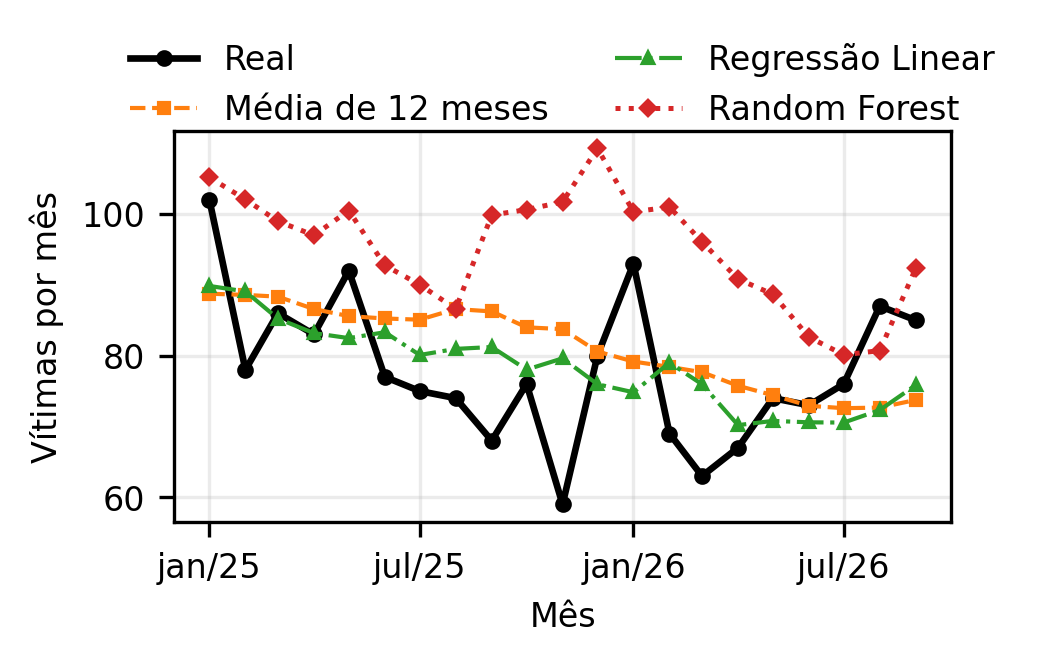

              y  media_12m  linear  random_forest
mes                                              
2025-01-01  102       88.8    89.8          105.2
2025-02-01   78       88.6    89.1          102.1
2025-03-01   86       88.3    85.2           99.0
2025-04-01   83       86.6    83.2           97.0
2025-05-01   92       85.6    82.5          100.5
2025-06-01   77       85.2    83.3           92.8
2025-07-01   75       85.1    80.1           90.0
2025-08-01   74       86.6    81.0           86.6
2025-09-01   68       86.2    81.2           99.9
2025-10-01   76       84.0    78.0          100.6
2025-11-01   59       83.8    79.6          101.7
2025-12-01   80       80.6    76.0          109.3
2026-01-01   93       79.2    74.8          100.3
2026-02-01   69       78.4    79.0          101.0
2026-03-01   63       77.7    76.0           96.1
2026-04-01   67       75.8    70.2           90.8
2026-05-01   74       74.4    70.8           88.7
2026-06-01   73       72.9    70.6           82.6


In [7]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

if not os.path.exists("painel.csv"):
    from google.colab import files
    files.upload()   # selecione o painel.csv

p = pd.read_csv("painel.csv")
p["mes"] = pd.to_datetime(p["mes"])
feats = ["lag1","lag2","lag3","lag6","lag12","roll3","roll12","m","ano","logpop"]
tr = p[p.mes < "2025-01-01"]
te = p[p.mes >= "2025-01-01"].copy()
print(p.shape, len(tr), "treino |", len(te), "teste")   # esperado: (16830, 14) 14688 treino | 2142 teste

lr = LinearRegression().fit(tr[feats], tr.y)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42).fit(tr[feats], tr.y)
te["media_12m"] = te["roll12"].values
te["linear"] = np.clip(lr.predict(te[feats]), 0, None)
te["random_forest"] = rf.predict(te[feats])
s = te.groupby("mes")[["y","media_12m","linear","random_forest"]].sum()

meses = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
os.makedirs("figuras", exist_ok=True)

fig, ax = plt.subplots(figsize=(3.5, 2.5), dpi=300)
ax.plot(s.index, s["y"], "k-o", ms=3, lw=1.6, label="Real")
ax.plot(s.index, s["media_12m"], "--s", color="tab:orange", ms=2.5, lw=1, label="Média de 12 meses")
ax.plot(s.index, s["linear"], "-.^", color="tab:green", ms=2.5, lw=1, label="Regressão Linear")
ax.plot(s.index, s["random_forest"], ":D", color="tab:red", ms=2.5, lw=1.2, label="Random Forest")

ax.set_xlabel("Mês", fontsize=8)
ax.set_ylabel("Vítimas por mês", fontsize=8)
ax.set_xticks(s.index[::6])
ax.set_xticklabels([f"{meses[d.month-1]}/{str(d.year)[2:]}" for d in s.index[::6]], fontsize=8)
ax.tick_params(axis="y", labelsize=8)
ax.legend(fontsize=8, ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.30))
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("figuras/rq3_previsto_real.png", dpi=300, bbox_inches="tight")
plt.show()
print(s.round(1))